# PRCP-1027: Skin Disorder Prediction
**Domain:** Healthcare  |  **Data:** UCI Dermatology (erythemato-squamous diseases), 366 patients, 34 attributes  |  **File:** `dataset_35_dermatology (1).csv` (place it next to this notebook)

| Deliverable | Where |
|---|---|
| Task 1: Data analysis report | Section 1 |
| Task 2: Predictive model | Sections 2 and 4 |
| Task 3: Suggestions to doctors | Section 3 |
| Model comparison report | Sections 2.2 to 2.7 |
| Report on challenges faced | Section 5 |

**Headline results**
* The tuned Random Forest classifies the six diseases with **97.3% accuracy (72 of 74) and 0.969 macro-F1 on a hold-out set**, and about 97–98% in repeated cross-validation.
* With **clinical features only** (no biopsy) accuracy falls to about **86%**, mostly because seborrheic dermatitis, chronic dermatitis and pityriasis rosea look alike. Two targeted histology findings recover most of the gap (Section 3).

In [23]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

# 1. Data Analysis Report

## 1.1 Loading the data

In [24]:
from pathlib import Path
path = Path.home() / "Downloads" / "PRCP-1028-Skin-Disorder-Prediction-20220512T101734Z-001" / "PRCP-1028-Skin-Disorder-Prediction" / "dataset_35_dermatology (1).csv"
df = pd.read_csv(path)

The target column is `class` (1–6). Using the dataset description, the codes map to the six diagnoses:

| Code | Disease |
|---|---|
| 1 | Psoriasis |
| 2 | Seborrheic dermatitis |
| 3 | Lichen planus |
| 4 | Pityriasis rosea |
| 5 | Chronic dermatitis |
| 6 | Pityriasis rubra pilaris |

The 33 predictors split into **11 clinical** features (observed at the visit, `family_history` is 0/1) and **22 histopathological** features (need a skin biopsy examined under a microscope), plus `Age`.

In [25]:
class_names = {1:"Psoriasis", 2:"Seborrheic dermatitis", 3:"Lichen planus",
               4:"Pityriasis rosea", 5:"Chronic dermatitis", 6:"Pityriasis rubra pilaris"}
clinical = list(df.columns[:11])
histo    = list(df.columns[11:33])
print("Clinical     :", len(clinical)); print("Histopathology:", len(histo))

Clinical     : 11
Histopathology: 22


## 1.2 Data quality: types, missing values, duplicates

In [26]:
df.info()
print("\nMissing (NaN):", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Non-numeric Age values:", sorted(df.loc[pd.to_numeric(df['Age'], errors='coerce').isna(), 'Age'].unique()))
print("Rows with '?' in Age:", (df['Age'] == '?').sum())

<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   erythema                                  366 non-null    int64
 1   scaling                                   366 non-null    int64
 2   definite_borders                          366 non-null    int64
 3   itching                                   366 non-null    int64
 4   koebner_phenomenon                        366 non-null    int64
 5   polygonal_papules                         366 non-null    int64
 6   follicular_papules                        366 non-null    int64
 7   oral_mucosal_involvement                  366 non-null    int64
 8   knee_and_elbow_involvement                366 non-null    int64
 9   scalp_involvement                         366 non-null    int64
 10  family_history                            366 non-null    int64
 11  mela

**Finding:** `Age` is stored as text because 8 patients have the placeholder `'?'`. `isna()` reports zero missing values, so this is a *hidden* missing-value problem. We convert `?` to `NaN` and impute later (inside the model pipeline, so no information leaks from the test set).

In [27]:
df["Age"] = pd.to_numeric(df["Age"].replace("?", np.nan))
print(df["Age"].isna().sum(), "missing ages")
df.loc[df["Age"].isna(), "class"].map(class_names).value_counts()

8 missing ages


class
Chronic dermatitis       4
Psoriasis                1
Pityriasis rosea         1
Seborrheic dermatitis    1
Lichen planus            1
Name: count, dtype: int64

## 1.3 Descriptive statistics

In [28]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.07,0.66,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.80,0.70,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.55,0.91,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.37,1.14,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.63,0.91,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.45,0.96,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.17,0.57,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.38,0.83,0.0,0.0,0.0,0.00,3.0
knee_and_elbow_involvement,366.0,0.61,0.98,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.52,0.91,0.0,0.0,0.0,1.00,3.0


Cell 7: Range checks

In [29]:
# Check that every ordinal feature stays inside its documented range (0-3, family_history 0/1)
ordinal = [c for c in df.columns if c not in ("Age", "class")]
print("Ordinal feature min/max:", df[ordinal].min().min(), "/", df[ordinal].max().max())
print("family_history values:", sorted(df["family_history"].unique()))
print("Age range:", df["Age"].min(), "-", df["Age"].max())

Ordinal feature min/max: 0 / 3
family_history values: [np.int64(0), np.int64(1)]
Age range: 0.0 - 75.0


## 1.4 Target distribution

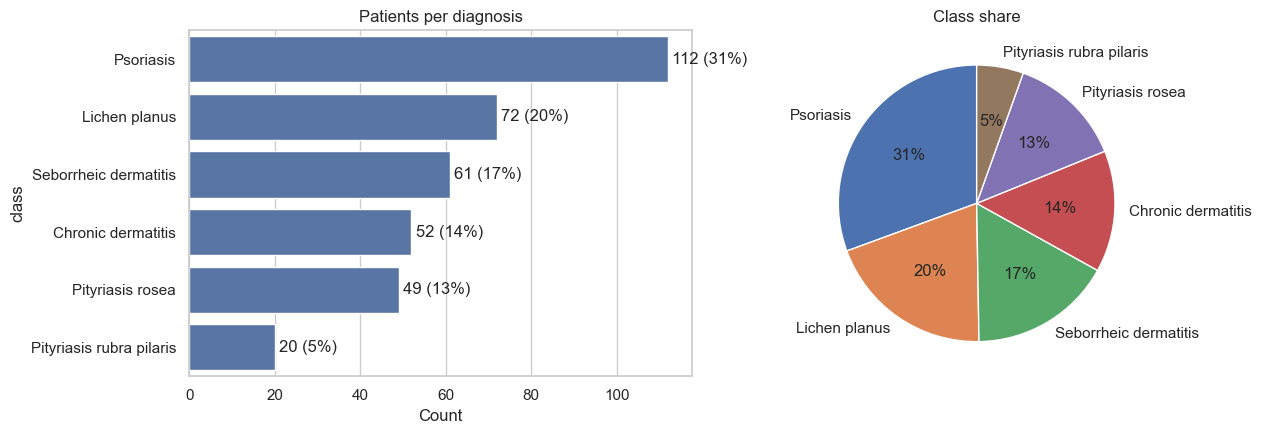

Imbalance ratio (largest/smallest): 5.6


In [30]:
counts = df["class"].map(class_names).value_counts()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=counts.values, y=counts.index, ax=ax[0], color="#4C72B0")
for i, v in enumerate(counts.values): ax[0].text(v + 1, i, f"{v} ({v/len(df):.0%})", va="center")
ax[0].set_title("Patients per diagnosis"); ax[0].set_xlabel("Count")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.0f%%", startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()
print("Imbalance ratio (largest/smallest):", round(counts.max()/counts.min(), 1))

**Observation:** Psoriasis is the largest class (31%) and Pityriasis rubra pilaris the smallest (about 5.5%), a ratio of roughly 5.6 : 1. The imbalance is moderate, so we use **stratified** splits and judge models on **macro-F1** as well as accuracy, so the small class is not ignored.

## 1.5 Age analysis

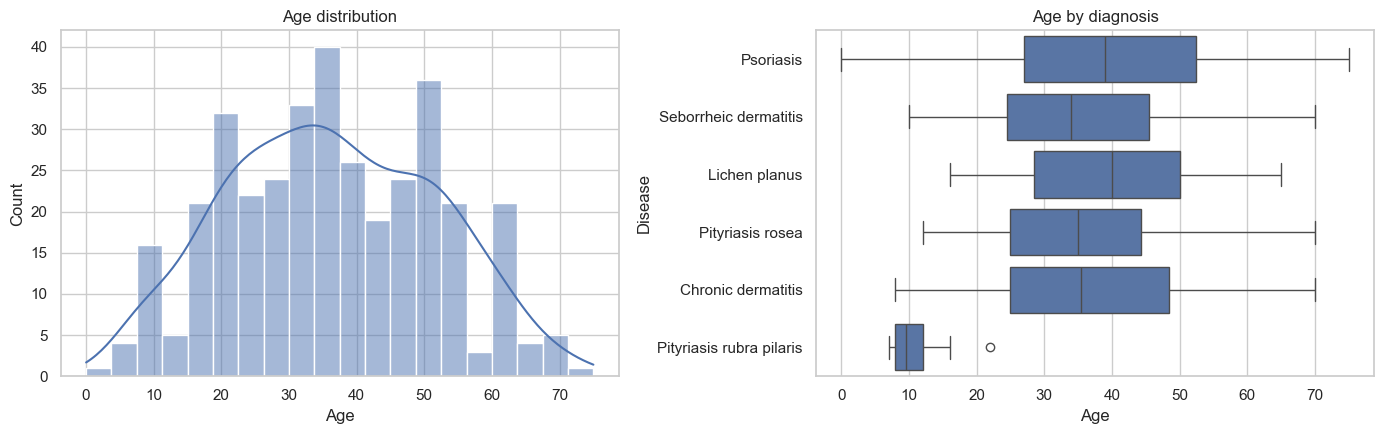

,count,mean,median,min,max
class,,,,,
Psoriasis,111,39.4,39.0,0.0,75.0
Seborrheic dermatitis,60,35.5,34.0,10.0,70.0
Lichen planus,71,40.0,40.0,16.0,65.0
Pityriasis rosea,48,35.3,35.0,12.0,70.0
Chronic dermatitis,48,36.7,35.5,8.0,70.0
Pityriasis rubra pilaris,20,10.2,9.5,7.0,22.0


In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["Age"].dropna(), bins=20, kde=True, ax=ax[0])
ax[0].set_title("Age distribution")
order = [class_names[i] for i in range(1, 7)]
sns.boxplot(data=df.assign(Disease=df["class"].map(class_names)), y="Disease", x="Age", order=order, ax=ax[1])
ax[1].set_title("Age by diagnosis")
plt.tight_layout(); plt.show()
df.groupby(df["class"].map(class_names))["Age"].agg(["count", "mean", "median", "min", "max"]).round(1).loc[order]

## 1.6 Feature profile of each disease

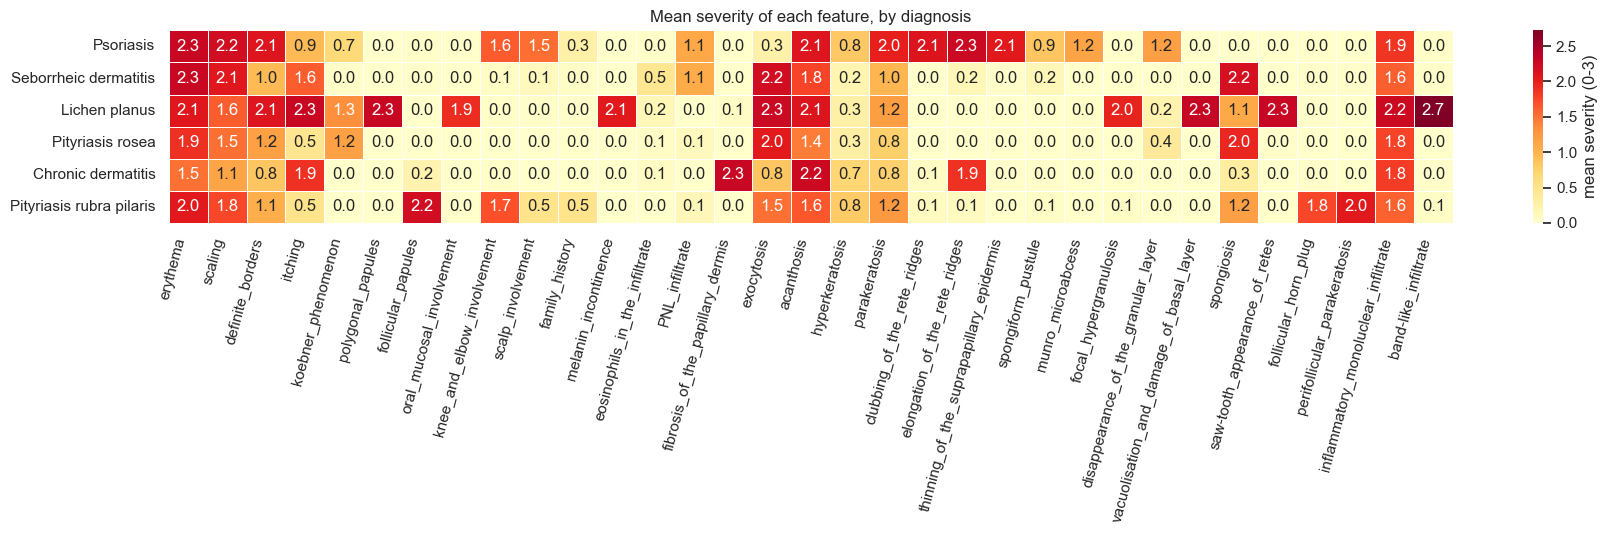

In [32]:
profile = df.groupby("class")[clinical + histo].mean()
profile.index = [class_names[i] for i in profile.index]
plt.figure(figsize=(18, 5.5))
sns.heatmap(profile, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "mean severity (0-3)"}, linewidths=.4)
plt.title("Mean severity of each feature, by diagnosis"); plt.xticks(rotation=75, ha="right")
plt.tight_layout(); plt.show()

Each disease has a distinctive 'signature'. Highlights visible in the heatmap: lichen planus lights up on `polygonal_papules`, `band-like_infiltrate` and `saw-tooth_appearance_of_retes`; pityriasis rubra pilaris on `follicular_papules`, `follicular_horn_plug` and `perifollicular_parakeratosis`; psoriasis on `munro_microabcess`, `clubbing_of_the_rete_ridges`, `thinning_of_the_suprapapillary_epidermis` and `scalp_involvement`; chronic dermatitis on `fibrosis_of_the_papillary_dermis`; seborrheic dermatitis on `spongiosis` and `exocytosis` (and the highest, though still low, `eosinophils_in_the_infiltrate`); and pityriasis rosea shares `spongiosis` and `exocytosis` with seborrheic dermatitis but has no knee/elbow or scalp involvement. `erythema` and `scaling` are present in every disease, so on their own they cannot discriminate.

## 1.7 Which features separate the classes?

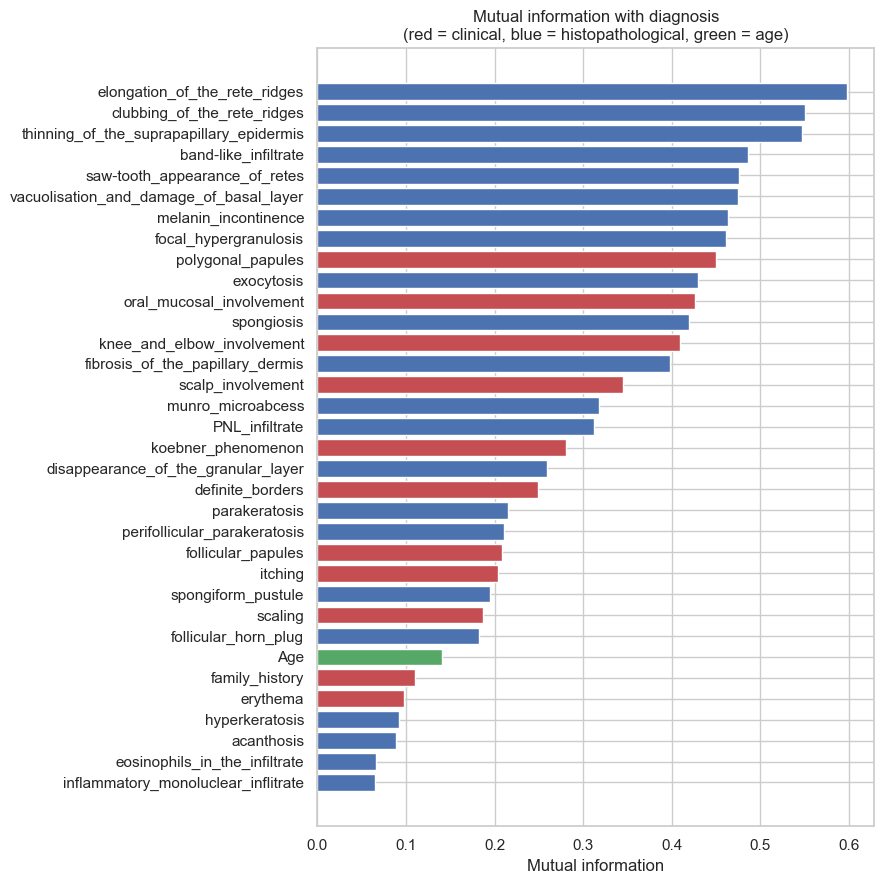

elongation_of_the_rete_ridges               0.598
clubbing_of_the_rete_ridges                 0.550
thinning_of_the_suprapapillary_epidermis    0.547
band-like_infiltrate                        0.486
saw-tooth_appearance_of_retes               0.476
vacuolisation_and_damage_of_basal_layer     0.475
melanin_incontinence                        0.463
focal_hypergranulosis                       0.461
polygonal_papules                           0.450
exocytosis                                  0.430
dtype: float64

In [33]:
from sklearn.feature_selection import mutual_info_classif
X_tmp = df.drop(columns="class").copy()
X_tmp["Age"] = X_tmp["Age"].fillna(X_tmp["Age"].median())
mi = pd.Series(mutual_info_classif(X_tmp, df["class"], discrete_features=[c != "Age" for c in X_tmp.columns], random_state=RANDOM_STATE),
               index=X_tmp.columns).sort_values(ascending=False)
colors = ["#C44E52" if c in clinical else "#4C72B0" if c in histo else "#55A868" for c in mi.index]
plt.figure(figsize=(9, 9)); plt.barh(mi.index[::-1], mi.values[::-1], color=colors[::-1])
plt.title("Mutual information with diagnosis\n(red = clinical, blue = histopathological, green = age)")
plt.xlabel("Mutual information"); plt.tight_layout(); plt.show()
mi.head(10).round(3)

Cell 12: Clinical vs histopathology information

In [34]:
print("Mean mutual information - clinical:", round(mi[clinical].mean(), 3),
      "| histopathological:", round(mi[histo].mean(), 3))

Mean mutual information - clinical: 0.27 | histopathological: 0.332


## 1.8 Correlation structure

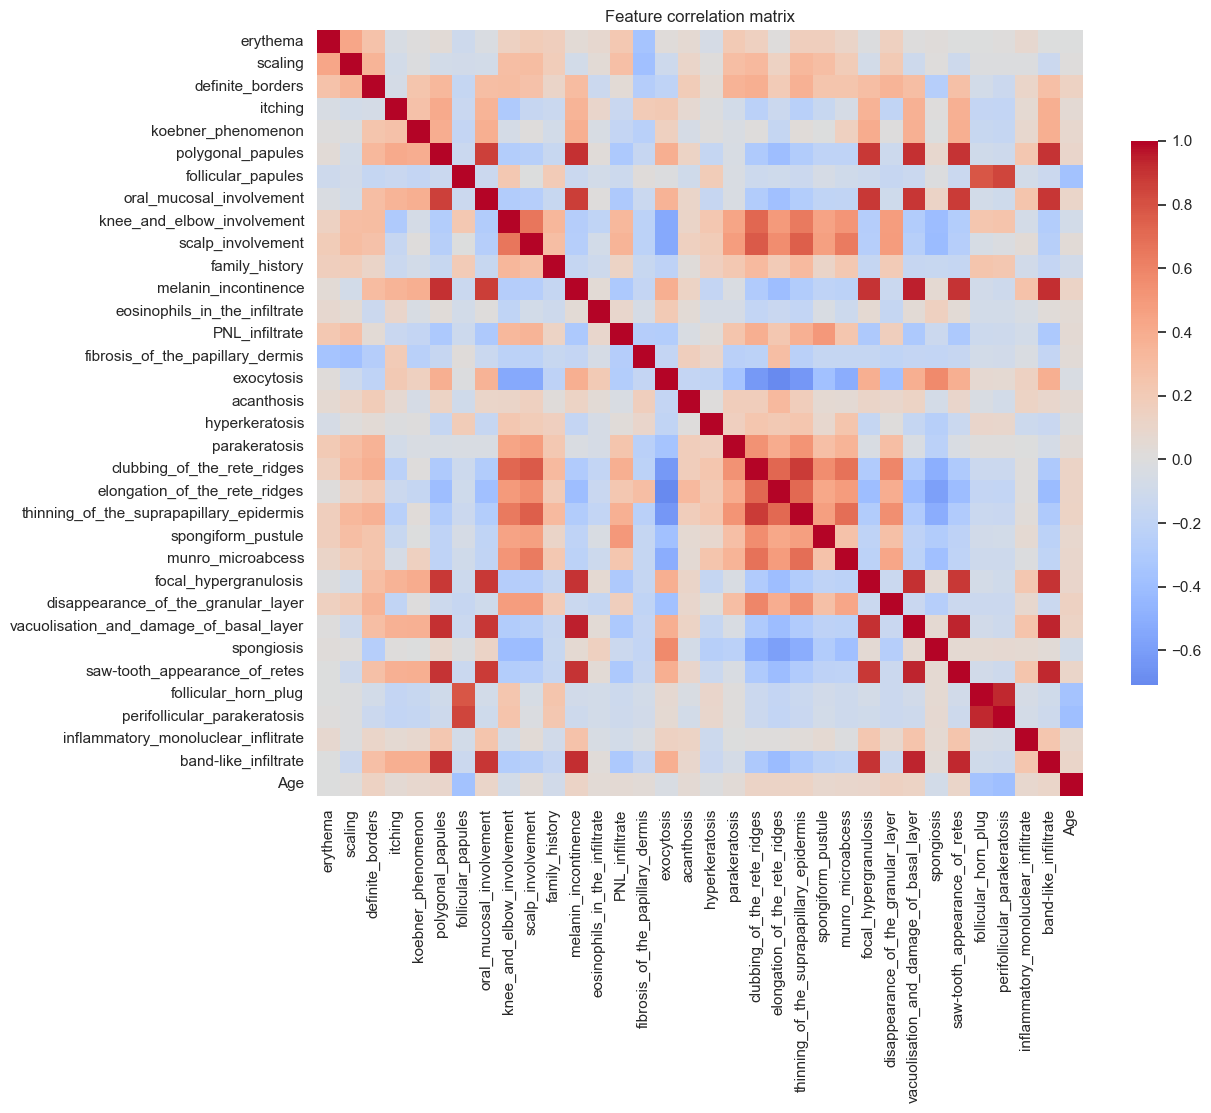

,level_0,level_1,corr
400,melanin_incontinence,vacuolisation_and_damage_of_basal_layer,0.94
912,vacuolisation_and_damage_of_basal_layer,saw-tooth_appearance_of_retes,0.94
916,vacuolisation_and_damage_of_basal_layer,band-like_infiltrate,0.94
1016,follicular_horn_plug,perifollicular_parakeratosis,0.93
984,saw-tooth_appearance_of_retes,band-like_infiltrate,0.93
406,melanin_incontinence,band-like_infiltrate,0.92
196,polygonal_papules,vacuolisation_and_damage_of_basal_layer,0.91
842,focal_hypergranulosis,vacuolisation_and_damage_of_basal_layer,0.91


In [35]:
corr = df.drop(columns="class").corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Feature correlation matrix"); plt.tight_layout(); plt.show()
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("corr").reset_index())
pairs["abs"] = pairs["corr"].abs()
pairs.sort_values("abs", ascending=False).head(8).drop(columns="abs").round(2)

Several histopathological features are strongly correlated (for example `melanin_incontinence`, `vacuolisation_and_damage_of_basal_layer`, `saw-tooth_appearance_of_retes` and `band-like_infiltrate` all correlate at about 0.92–0.94, as do `follicular_horn_plug` and `perifollicular_parakeratosis`; `clubbing_of_the_rete_ridges` and `elongation_of_the_rete_ridges` correlate at about 0.72). This is expected because they describe overlapping features of the same tissue changes. It matters for the choice of model: tree ensembles and regularised models cope with this redundancy well.

## 1.9 Clinical-only vs. histopathology: how much does the biopsy add?

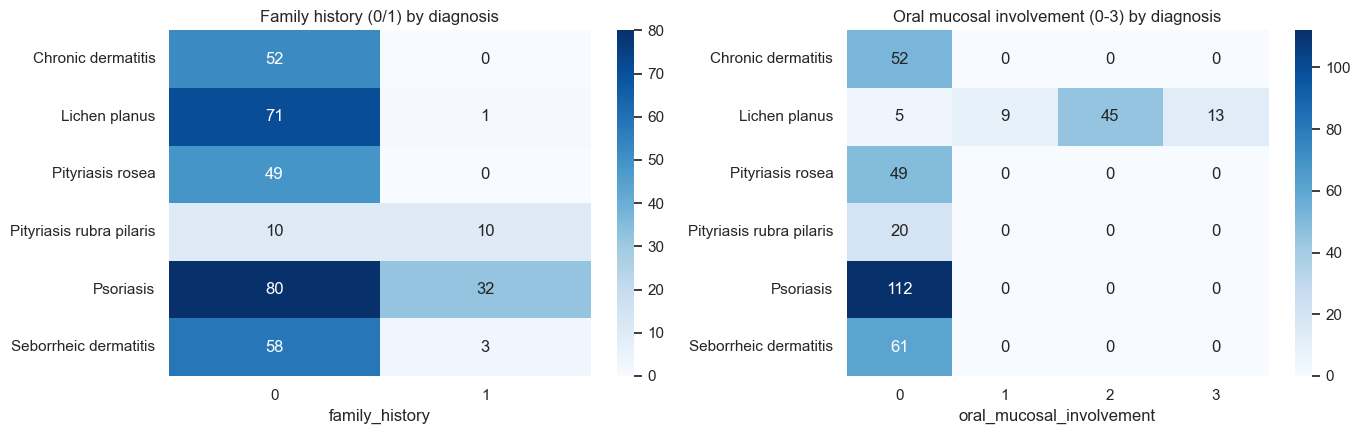

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(pd.crosstab(df["class"].map(class_names), df["family_history"]), annot=True, fmt="d", cmap="Blues", ax=ax[0])
ax[0].set_title("Family history (0/1) by diagnosis"); ax[0].set_ylabel("")
sns.heatmap(pd.crosstab(df["class"].map(class_names), df["oral_mucosal_involvement"]), annot=True, fmt="d", cmap="Blues", ax=ax[1])
ax[1].set_title("Oral mucosal involvement (0-3) by diagnosis"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Observations**
* `oral_mucosal_involvement` is non-zero for 67 of the 72 lichen planus patients and for **no** patient with any other disease, making it a very strong clinical pointer to lichen planus.
* `family_history` is positive for 32 of 112 psoriasis patients and 10 of 20 pityriasis rubra pilaris patients, and almost never for the other diseases.
* Most histopathological findings are absent (score 0) for the large majority of patients (87–94% zeros for the sparsest ones), because each finding is characteristic of only one or two diseases.
* Pityriasis rubra pilaris is a disease of the young in this data: all 20 patients are aged 7–22 (mean about 10), while the other five diseases average 35–40 years.

# 2. Predictive Model

## 2.1 Modelling set-up

* **Target:** `class` (6 diagnoses).
* **Split:** 80 / 20 stratified hold-out (the test set is touched only once, at the end).
* **Imputation:** the 8 missing ages are filled with the training-set median *inside* each pipeline, so cross-validation never sees the validation fold's statistics.
* **Scaling:** applied only to models that need it (Logistic Regression, KNN, SVM).
* **Metrics:** accuracy and macro-F1 (macro-F1 gives the small classes equal weight).

In [37]:
X = df.drop(columns="class")
y = df["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print(y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

Train: (292, 34) | Test: (74, 34)
{1: 0.305, 2: 0.168, 3: 0.195, 4: 0.134, 5: 0.144, 6: 0.055}
{1: 0.311, 2: 0.162, 3: 0.203, 4: 0.135, 5: 0.135, 6: 0.054}


## 2.2 Candidate models, compared with repeated stratified cross-validation

In [38]:
def make(model, scale=False):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale: steps.append(("scale", StandardScaler()))
    steps.append(("clf", model))
    return Pipeline(steps)

models = {
    "Logistic Regression": make(LogisticRegression(max_iter=3000, C=1.0), scale=True),
    "KNN":                 make(KNeighborsClassifier(n_neighbors=7), scale=True),
    "SVM (RBF)":           make(SVC(C=10, gamma="scale", probability=True, random_state=RANDOM_STATE), scale=True),
    "Naive Bayes":         make(GaussianNB()),
    "Decision Tree":       make(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Random Forest":       make(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)),
    "Extra Trees":         make(ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE)),
    "Gradient Boosting":   make(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({"Model": name,
                 "CV accuracy": res["test_accuracy"].mean(), "CV acc std": res["test_accuracy"].std(),
                 "CV macro-F1": res["test_f1_macro"].mean()})
cv_table = pd.DataFrame(rows).sort_values("CV macro-F1", ascending=False).reset_index(drop=True)
cv_table.round(4)

,Model,CV accuracy,CV acc std,CV macro-F1
0,Extra Trees,0.9817,0.0098,0.9794
1,Logistic Regression,0.9738,0.0174,0.9703
2,Random Forest,0.9749,0.0165,0.9684
3,SVM (RBF),0.9703,0.0159,0.9661
4,KNN,0.9681,0.0214,0.9654
5,Gradient Boosting,0.9589,0.0224,0.9507
6,Decision Tree,0.9509,0.0185,0.9383
7,Naive Bayes,0.8984,0.0148,0.8804


## 2.3 Hold-out test performance of every model

In [39]:
rows = []
fitted = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train); fitted[name] = pipe
    pred = pipe.predict(X_test)
    rows.append({"Model": name, "Test accuracy": accuracy_score(y_test, pred),
                 "Test macro-F1": f1_score(y_test, pred, average="macro")})
test_table = pd.DataFrame(rows)
comparison = cv_table.merge(test_table, on="Model").sort_values("CV macro-F1", ascending=False).reset_index(drop=True)
comparison.round(4)

,Model,CV accuracy,CV acc std,CV macro-F1,Test accuracy,Test macro-F1
0,Extra Trees,0.9817,0.0098,0.9794,0.9595,0.9545
1,Logistic Regression,0.9738,0.0174,0.9703,0.9595,0.9574
2,Random Forest,0.9749,0.0165,0.9684,0.9595,0.9545
3,SVM (RBF),0.9703,0.0159,0.9661,0.9730,0.9697
4,KNN,0.9681,0.0214,0.9654,0.9054,0.9034
5,Gradient Boosting,0.9589,0.0224,0.9507,0.9324,0.9125
6,Decision Tree,0.9509,0.0185,0.9383,0.9324,0.8878
7,Naive Bayes,0.8984,0.0148,0.8804,0.8649,0.8224


**Reading the comparison**
* The five best models (Extra Trees, Logistic Regression, Random Forest, SVM, KNN) are within about 1.4 accuracy points of each other in cross-validation, which is roughly one standard deviation of the fold-to-fold scores (0.010–0.021). **The data cannot separate them with confidence.**
* The hold-out set has only 74 patients, so a single patient is worth 1.35 accuracy points. Differences such as 0.973 (SVM) vs 0.960 (Extra Trees) on the hold-out set are one patient and should not be over-read.
* **Naive Bayes is clearly worst** (CV accuracy 0.898). It assumes features are independent given the class, but many histopathology findings are correlated at 0.9 or more (Section 1.8).
* **KNN** drops from 0.968 in CV to 0.905 on the hold-out set, a sign of higher variance. **Gradient Boosting** (0.959) and a single **Decision Tree** (0.951) trail the bagged forests, which is common on small data, where averaging many de-correlated trees is more stable than boosting.

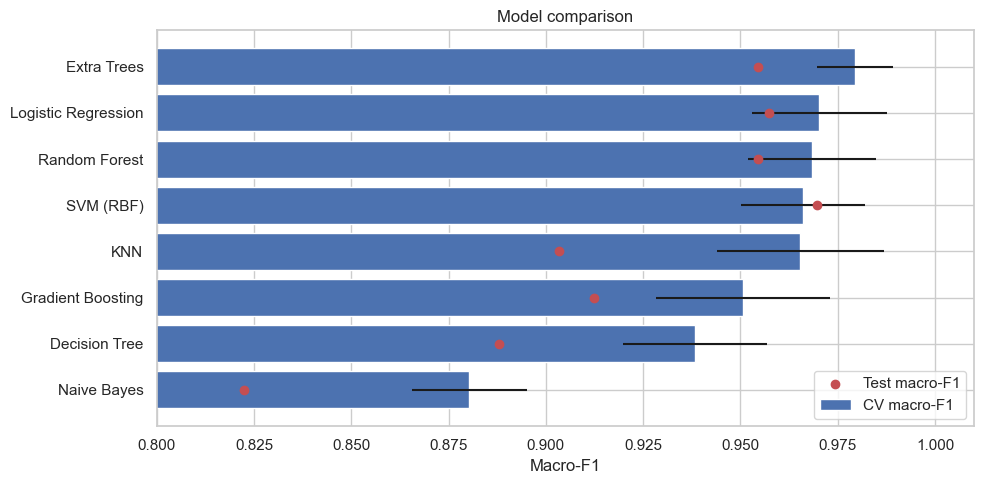

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
c = comparison.sort_values("CV macro-F1")
ax.barh(c["Model"], c["CV macro-F1"], xerr=c["CV acc std"], color="#4C72B0", label="CV macro-F1")
ax.scatter(c["Test macro-F1"], c["Model"], color="#C44E52", zorder=3, label="Test macro-F1")
ax.set_xlim(0.8, 1.01); ax.set_xlabel("Macro-F1"); ax.legend(loc="lower right")
ax.set_title("Model comparison"); plt.tight_layout(); plt.show()

## 2.4 Tuning the top candidates

In [41]:
grids = {
    "SVM (RBF)": (make(SVC(probability=True, random_state=RANDOM_STATE), scale=True),
                  {"clf__C": [1, 3, 10, 30, 100], "clf__gamma": ["scale", 0.01, 0.03, 0.1]}),
    "Logistic Regression": (make(LogisticRegression(max_iter=5000), scale=True),
                            {"clf__C": [0.03, 0.1, 0.3, 1, 3, 10]}),
    "Random Forest": (make(RandomForestClassifier(random_state=RANDOM_STATE)),
                      {"clf__n_estimators": [200, 500], "clf__max_depth": [None, 6, 10], "clf__min_samples_leaf": [1, 2]}),
}
tuned, rows = {}, []
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=inner, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    pred = gs.predict(X_test)
    rows.append({"Model": name, "Best params": gs.best_params_, "Tuned CV macro-F1": gs.best_score_,
                 "Test accuracy": accuracy_score(y_test, pred), "Test macro-F1": f1_score(y_test, pred, average="macro")})
pd.DataFrame(rows).round(4)

,Model,Best params,Tuned CV macro-F1,Test accuracy,Test macro-F1
0,SVM (RBF),"{'clf__C': 1, 'clf__gamma': 0.01}",0.9768,0.9595,0.9545
1,Logistic Regression,{'clf__C': 10},0.9768,0.9595,0.9574
2,Random Forest,"{'clf__max_depth': 6, 'clf__min_samples_leaf':...",0.9770,0.9730,0.9694


After tuning, Random Forest (0.9770), SVM (0.9768) and Logistic Regression (0.9768) are **effectively tied** on cross-validated macro-F1. Extra Trees led the untuned comparison but was not carried into tuning; as a close relative of Random Forest it would be a reasonable alternative.

## 2.5 Final model evaluation

Selected model (by cross-validated macro-F1): Random Forest
                          precision    recall  f1-score   support

               Psoriasis      1.000     1.000     1.000        23
   Seborrheic dermatitis      0.917     0.917     0.917        12
           Lichen planus      1.000     1.000     1.000        15
        Pityriasis rosea      0.900     0.900     0.900        10
      Chronic dermatitis      1.000     1.000     1.000        10
Pityriasis rubra pilaris      1.000     1.000     1.000         4

                accuracy                          0.973        74
               macro avg      0.969     0.969     0.969        74
            weighted avg      0.973     0.973     0.973        74



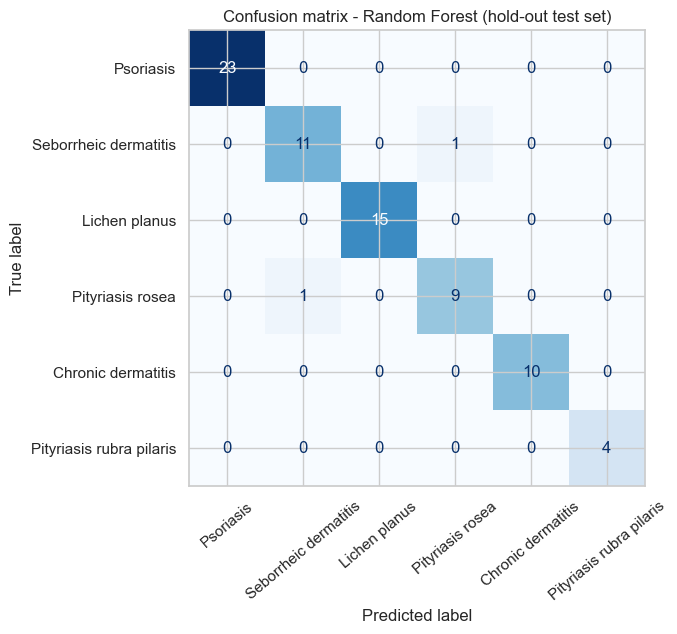

In [42]:
tune_df = pd.DataFrame(rows).set_index("Model")
best_name = tune_df["Tuned CV macro-F1"].idxmax()   # selected on CV only, never on the test set
best = tuned[best_name]
print("Selected model (by cross-validated macro-F1):", best_name)
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=[class_names[i] for i in range(1, 7)], digits=3))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=[class_names[i] for i in range(1, 7)],
                                        xticks_rotation=40, cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix - {best_name} (hold-out test set)"); plt.tight_layout(); plt.show()

**Result on the untouched hold-out set:** 72 of 74 patients correct (97.3%), macro-F1 0.969. Four of the six diseases (psoriasis, lichen planus, chronic dermatitis, pityriasis rubra pilaris) were classified perfectly. The two errors are one seborrheic dermatitis and one pityriasis rosea patient who were confused with each other, which matches the overlap seen in Section 3. With 74 patients the uncertainty is wide, so the cross-validated figure (about 97–98%) is the better guide.

## 2.6 What drives the predictions?

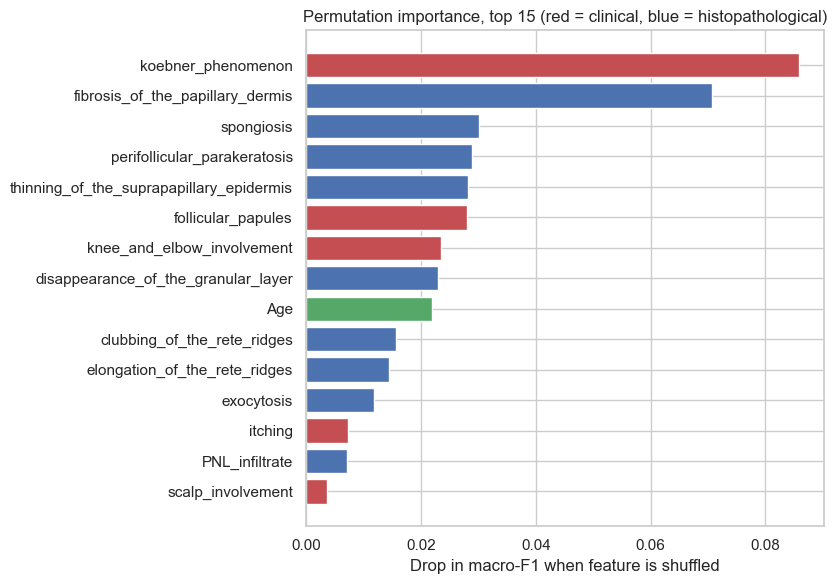

In [43]:
pi = permutation_importance(best, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="f1_macro")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
top = imp.head(15)
colors = ["#C44E52" if c in clinical else "#4C72B0" if c in histo else "#55A868" for c in top.index]
plt.figure(figsize=(8.5, 6)); plt.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
plt.title("Permutation importance, top 15 (red = clinical, blue = histopathological)")
plt.xlabel("Drop in macro-F1 when feature is shuffled"); plt.tight_layout(); plt.show()

Cell 22: Random Forest importances (cross-check)

In [44]:
# Random-forest importances are more stable on small data, so we cross-check with them
rf = make(RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE)).fit(X_train, y_train)
rf_imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=X.columns).sort_values(ascending=False)
rf_imp.head(12).round(3)

clubbing_of_the_rete_ridges                 0.097
fibrosis_of_the_papillary_dermis            0.080
thinning_of_the_suprapapillary_epidermis    0.077
koebner_phenomenon                          0.066
elongation_of_the_rete_ridges               0.060
spongiosis                                  0.056
vacuolisation_and_damage_of_basal_layer     0.040
focal_hypergranulosis                       0.039
PNL_infiltrate                              0.038
band-like_infiltrate                        0.038
melanin_incontinence                        0.036
saw-tooth_appearance_of_retes               0.031
dtype: float64

**Reading the importances.** Histopathological findings dominate the ranking: `clubbing_of_the_rete_ridges`, `fibrosis_of_the_papillary_dermis`, `thinning_of_the_suprapapillary_epidermis` and `elongation_of_the_rete_ridges` are all in the top five, and `koebner_phenomenon` is the only clinical feature among them. Correlated features share credit, so each individual value understates how informative that finding is on its own. These are statistical associations in this dataset, not causal statements.

## 2.7 Model Comparison Report: recommendation for production

| Model | CV accuracy | CV macro-F1 | Hold-out accuracy | Verdict |
|---|---|---|---|---|
| Extra Trees | 0.982 | 0.979 | 0.960 | Strong; not tuned |
| Random Forest | 0.975 | 0.968 (0.977 tuned) | 0.960 (0.973 tuned) | **Recommended** |
| Logistic Regression | 0.974 | 0.970 (0.977 tuned) | 0.960 | Strong, simple baseline |
| SVM (RBF) | 0.970 | 0.966 (0.977 tuned) | 0.973 (0.960 tuned) | Strong, less interpretable |
| KNN | 0.968 | 0.965 | 0.905 | Higher variance |
| Gradient Boosting | 0.959 | 0.951 | 0.932 | Weaker on 292 training rows |
| Decision Tree | 0.951 | 0.938 | 0.932 | Unstable single tree |
| Naive Bayes | 0.898 | 0.880 | 0.865 | Independence assumption violated |

**Recommendation: tuned Random Forest.** Accuracy is statistically tied with the other top models, so the choice rests on practical grounds:
1. It copes with the strongly correlated features and needs no scaling or encoding of the 0–3 scores.
2. It gives feature importances and **class probabilities**, so a doctor can see "Seborrheic dermatitis 64%, Pityriasis rosea 23%" rather than a bare label (Section 4).
3. It was the best model on cross-validated macro-F1 after tuning, and it performed well on the hold-out set without having been selected on it.

**Before production:** validate on data from other hospitals and scanners/pathologists, because all 366 patients come from one source and one class (pityriasis rubra pilaris) has only 20 patients. Treat the model as decision support, not as an automatic diagnosis.

# 3. Suggestions to Doctors: identifying the disease earlier

The central clinical question: *can a diagnosis be made before waiting for biopsy results?* We test this directly by training the same model on three feature sets and evaluating each with repeated cross-validation on the full data set.

In [45]:
def cv_score(cols, model_name="Random Forest"):
    model = {"Random Forest": make(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)),
             "SVM": make(SVC(C=10, gamma="scale", random_state=RANDOM_STATE), scale=True)}[model_name]
    r = cross_validate(model, X[cols], y, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    return r["test_accuracy"].mean(), r["test_f1_macro"].mean()

sets = {
    "Clinical only (11) + Age": clinical + ["Age"],
    "Histopathology only (22) + Age": histo + ["Age"],
    "All features (33) + Age": list(X.columns),
}
out = []
for k, cols in sets.items():
    a, f = cv_score(cols); out.append({"Feature set": k, "Accuracy": a, "Macro-F1": f})
feat_cmp = pd.DataFrame(out); feat_cmp.round(4)

,Feature set,Accuracy,Macro-F1
0,Clinical only (11) + Age,0.8643,0.8489
1,Histopathology only (22) + Age,0.9435,0.9362
2,All features (33) + Age,0.9727,0.9673


Cell 24: Per-disease recall by feature set

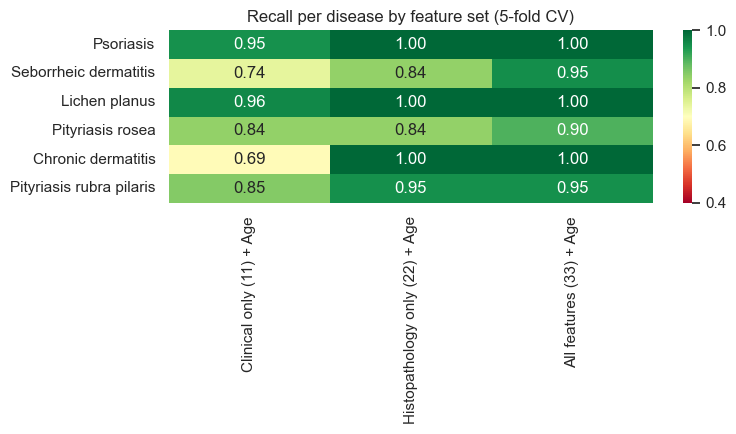

In [46]:
# Per-disease recall: which diseases are hard to tell apart WITHOUT a biopsy?
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
recalls = {}
for k, cols in sets.items():
    p = cross_val_predict(make(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)), X[cols], y, cv=skf)
    recalls[k] = recall_score(y, p, average=None)
rec = pd.DataFrame(recalls, index=[class_names[i] for i in range(1, 7)])
plt.figure(figsize=(8, 4.5)); sns.heatmap(rec, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.4, vmax=1)
plt.title("Recall per disease by feature set (5-fold CV)"); plt.tight_layout(); plt.show()

Cell 25: Confusions with clinical features only

In [47]:
# Confusions that remain with clinical features only
p = cross_val_predict(make(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)), X[sets["Clinical only (11) + Age"]], y, cv=skf)
cm = pd.crosstab(pd.Series(y.map(class_names), name="Actual"), pd.Series(pd.Series(p).map(class_names).values, index=y.index, name="Predicted"))
cm

Predicted,Chronic dermatitis,Lichen planus,Pityriasis rosea,Pityriasis rubra pilaris,Psoriasis,Seborrheic dermatitis
Actual,,,,,,
Chronic dermatitis,36,0,5,1,0,10
Lichen planus,0,69,2,0,1,0
Pityriasis rosea,5,0,41,0,0,3
Pityriasis rubra pilaris,1,0,0,17,2,0
Psoriasis,0,0,3,0,106,3
Seborrheic dermatitis,8,0,5,0,3,45


Cell 26: Top clinical features

In [48]:
# A short clinical checklist: the top-ranked clinical features and how each disease scores on them
rf_clin = make(RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE)).fit(X[clinical + ["Age"]], y)
ci = pd.Series(rf_clin.named_steps["clf"].feature_importances_, index=clinical + ["Age"]).sort_values(ascending=False)
print(ci.round(3).to_string())

Age                           0.127
polygonal_papules             0.126
knee_and_elbow_involvement    0.109
scalp_involvement             0.109
koebner_phenomenon            0.100
oral_mucosal_involvement      0.099
definite_borders              0.075
scaling                       0.072
itching                       0.067
follicular_papules            0.061
erythema                      0.042
family_history                0.012


Cell 27: Which biopsy findings add the most (greedy forward selection)

In [49]:
# Which histopathological findings add the most on top of the clinical picture? (greedy forward selection)
# NOTE: selection and scoring use the same folds, so these numbers are slightly optimistic. Read them as a ranking, not a final accuracy.
skf7 = StratifiedKFold(5, shuffle=True, random_state=7)
chosen, remaining, trace = clinical + ["Age"], list(histo), []
trace.append(("(clinical baseline)", cross_val_score(best, X[chosen], y, cv=skf7, scoring="accuracy").mean()))
for _ in range(5):
    scores = {f: cross_val_score(best, X[chosen + [f]], y, cv=skf7, scoring="accuracy").mean() for f in remaining}
    f = max(scores, key=scores.get); chosen.append(f); remaining.remove(f); trace.append((f"+ {f}", scores[f]))
pd.DataFrame(trace, columns=["Step", "CV accuracy"]).round(3)

,Step,CV accuracy
0,(clinical baseline),0.888
1,+ fibrosis_of_the_papillary_dermis,0.937
2,+ thinning_of_the_suprapapillary_epidermis,0.970
3,+ disappearance_of_the_granular_layer,0.970
4,+ exocytosis,0.976
5,+ spongiform_pustule,0.976


## 3.1 Suggestions to doctors

The results above translate into the following practical suggestions. They come from patterns in this dataset and should be reviewed by dermatologists before any change in practice.

1. **Start from the clinical picture, but do not stop there.** Clinical features alone give about 86% accuracy (macro-F1 0.85), against about 94% for histopathology alone and about 97% for both. Clinical scoring is good for triage and for choosing which biopsy findings to ask for, but it is not enough for a final diagnosis.
2. **Three diseases can often be recognised at the first visit.**
   * *Lichen planus* (69 of 72 correct on clinical features alone): polygonal papules, and oral mucosal involvement, which is present in 67 of 72 lichen planus patients and in no patient with any other disease here.
   * *Psoriasis* (106 of 112 correct): knee and elbow involvement, scalp involvement and a positive family history (32 of 112 patients).
   * *Pityriasis rubra pilaris* (17 of 20 correct): follicular papules, knee and elbow involvement, and **young age** (all 20 patients were 7–22 years old).
3. **Three diseases are hard to tell apart without a biopsy: seborrheic dermatitis, chronic dermatitis and pityriasis rosea.** With clinical features only, 36 of the 52 errors (about 70%) are confusions *among these three*, for example 10 chronic dermatitis patients labelled seborrheic dermatitis and 8 the other way round. For these, request the biopsy early rather than treating empirically.
4. **Ask the pathologist for a short list of high-value findings first.** Starting from the clinical features (CV accuracy 0.888), adding `fibrosis_of_the_papillary_dermis` (typical of chronic dermatitis, mean score 2.3 vs 0.1 or lower elsewhere) lifts it to 0.937, and adding `thinning_of_the_suprapapillary_epidermis` (typical of psoriasis, 2.1 vs 0 elsewhere) to 0.970. Five findings reach 0.976, in line with the full feature set (0.973 in the comparison above). Two or three findings reported quickly can therefore give most of the benefit of the full histology. *These figures come from a greedy search scored on the same folds, so they are optimistic and should be confirmed on new patients.*
5. **Use probabilities to decide who needs more work-up.** Show the top two diagnoses with their probabilities. When the leading probability is not clearly ahead of the second (as in the 64% vs 23% example in Section 4), treat it as an uncertain case: biopsy, specialist review or a follow-up visit. The exact cut-off should be set with clinicians on local data.
6. **Re-assess at follow-up.** The dataset description notes that a disease can show features of another disease at an early stage. A "low-confidence" patient is a good candidate for re-scoring after a short interval.
7. **Record data consistently.** Age was missing for 8 patients and is one of the most useful clinical features; the 0–3 scoring needs clear definitions so different clinicians score the same way.

# 4. Final model for deployment

In [50]:
import joblib
final_model = best.fit(X, y)                       # refit the selected, tuned pipeline on all 366 patients
joblib.dump(final_model, "skin_disorder_model.joblib")

# Demonstration: ranked probabilities for 3 patients (these rows were in the training data, so this only shows the output format)
proba = final_model.predict_proba(X.iloc[[0, 1, 2]])
for i, p in enumerate(proba):
    top2 = np.argsort(p)[::-1][:2]
    print(f"Patient {i}: " + " | ".join(f"{class_names[final_model.classes_[j]]} {p[j]:.0%}" for j in top2))

Patient 0: Seborrheic dermatitis 64% | Pityriasis rosea 23%
Patient 1: Psoriasis 97% | Pityriasis rubra pilaris 1%
Patient 2: Lichen planus 100% | Pityriasis rosea 0%


In [ ]:
# 5. Report on Challenges Faced

| # | Challenge in the data | Technique used | Why |
|---|---|---|---|
| 1 | **Hidden missing values.** `Age` was read as text because 8 patients have `?`, and `isna()` reported zero missing values. | Converted `?` to `NaN`, then filled with the **training-set median inside the model pipeline**. | Only 8 of 366 rows (2.2%), so dropping them would waste data. The median is robust to skew. Doing it inside the pipeline stops the validation folds influencing the fill value, and a per-class median was avoided because it would use the target (leakage). Half of the missing ages (4 of 8) belong to chronic dermatitis, so the imputation is not perfectly neutral for that class. |
| 2 | **Very small data set** (366 rows; 74 in the test set). One split gives noisy estimates. | **Stratified** split, **repeated stratified 5-fold CV** for all model selection, hold-out used once at the end. | Repeating the CV reduces dependence on a lucky split. We also avoided over-interpreting gaps smaller than about 1.5 points, because one test patient is worth 1.35 points. |
| 3 | **Class imbalance** (112 psoriasis vs 20 pityriasis rubra pilaris, about 5.6 : 1). | Stratified splits, **macro-F1** alongside accuracy, per-class recall reporting. | Macro-F1 gives the small class equal weight. We did not use SMOTE or other oversampling because the imbalance is moderate, and synthetic rows with non-integer scores would not be valid 0–3 clinical grades. |
| 4 | **Multicollinearity.** Many histopathology features correlate at 0.9–0.94. | Kept all features and used **tree ensembles and regularised Logistic Regression**; did not interpret single coefficients. | Dropping correlated findings would discard information that sometimes differs between diseases, and ensembles tolerate redundancy. Naive Bayes, which assumes independence, was the worst model (CV 0.898), which confirms the issue. |
| 5 | **Ordinal 0–3 features with a 0/1 flag and one continuous column.** | Treated scores as ordered numbers; **no one-hot encoding**; scaling only inside the pipelines of Logistic Regression, KNN and SVM. | One-hot encoding would multiply 33 columns by up to four levels on only 292 training rows. Trees are unaffected by scale. |
| 6 | **Risk of over-fitting and of optimistic reporting.** | Everything in `Pipeline`s; hyper-parameters tuned by CV on the training set only; the **model was chosen on CV, never on the test set**. | Choosing on the test set would make the reported hold-out score optimistic. |
| 7 | **Near-tie between several good models.** | Compared on CV mean and spread, hold-out result, interpretability and probability output, and chose Random Forest on those practical grounds. | A 0.1-point difference in CV macro-F1 is noise; a model that gives probabilities and importances is more useful to clinicians. |
| 8 | **Domain challenge: the biopsy delays diagnosis.** | Re-trained the same model on clinical-only, histopathology-only and all features, and examined per-class errors and a greedy feature search. | This turns the brief's question ("identify earlier") into measurable numbers (Section 3). |
| 9 | **Possible data-entry issue.** One psoriasis record has `Age = 0`. | Kept it, but flagged it. | Infantile psoriasis is possible, and one row has negligible effect. It should be checked at the source. |

**Checks that found no problem:** no duplicate rows, all 0–3 scores and the 0/1 family-history flag are within their documented ranges.

# 6. Conclusion

* The six erythemato-squamous diseases can be separated with about **97–98% accuracy** using clinical plus histopathological features; the tuned **Random Forest** is recommended, mainly for its stability, probability output and interpretability.
* **Clinical features alone reach about 86%.** Lichen planus, psoriasis and pityriasis rubra pilaris are often identifiable at the first visit, whereas **seborrheic dermatitis, chronic dermatitis and pityriasis rosea need histology.**
* Asking the pathologist for a few high-value findings first (such as papillary-dermis fibrosis and thinning of the suprapapillary epidermis) captures most of the benefit of the full biopsy report.
* **Limitations:** a single source, 366 patients, only 20 in the smallest class, and a 74-patient hold-out set. External validation is required before clinical use.